# Module 02 — Understanding Gradients and Training Stability

This notebook explores gradient direction, gradient magnitude, vanishing and exploding gradients, learning-rate stability, and practical gradient diagnostics.

## 1. A scalar gradient step

For the loss `L = (w - 5)²`, the gradient is `2 * (w - 5)`.

In [1]:
def scalar_step(weight, learning_rate=0.1):
    loss = (weight - 5.0) ** 2
    gradient = 2.0 * (weight - 5.0)
    next_weight = weight - learning_rate * gradient
    return loss, gradient, next_weight


for weight in (2.0, 5.0, 8.0):
    loss, gradient, next_weight = scalar_step(weight)
    print(
        f"w={weight:>3.1f} | "
        f"loss={loss:>5.2f} | "
        f"gradient={gradient:>5.2f} | "
        f"next_w={next_weight:>5.2f}"
    )

w=2.0 | loss= 9.00 | gradient=-6.00 | next_w= 2.60
w=5.0 | loss= 0.00 | gradient= 0.00 | next_w= 5.00
w=8.0 | loss= 9.00 | gradient= 6.00 | next_w= 7.40


## 2. Gradient norms through a deep linear stack

The model deliberately omits residual connections and normalization so the effect of repeated scaling is visible.

scale=0.5: first=1.705e-12, last=1.705e-12
scale=1.0: first=7.947e-01, last=7.947e-01
scale=1.5: first=6.092e+06, last=6.092e+06


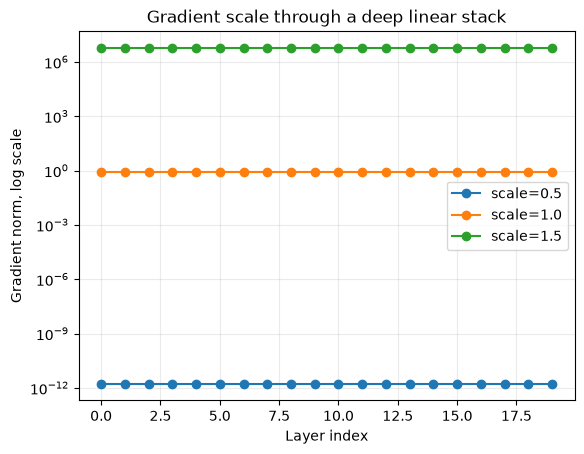

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)


class DeepLinear(nn.Module):
    def __init__(self, depth=20, scale=1.0):
        super().__init__()
        self.layers = nn.ModuleList()
        for _ in range(depth):
            layer = nn.Linear(32, 32, bias=False)
            nn.init.orthogonal_(layer.weight)
            with torch.no_grad():
                layer.weight.mul_(scale)
            self.layers.append(layer)

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


def inspect_gradients(scale, depth=20):
    model = DeepLinear(depth=depth, scale=scale)
    x = torch.randn(8, 32)
    objective = model(x).square().mean()
    objective.backward()
    return [layer.weight.grad.norm().item() for layer in model.layers]


scales = (0.5, 1.0, 1.5)
gradient_by_scale = {scale: inspect_gradients(scale) for scale in scales}

for scale, values in gradient_by_scale.items():
    print(f"scale={scale}: first={values[0]:.3e}, last={values[-1]:.3e}")

for scale, values in gradient_by_scale.items():
    plt.semilogy(values, marker="o", label=f"scale={scale}")

plt.xlabel("Layer index")
plt.ylabel("Gradient norm, log scale")
plt.title("Gradient scale through a deep linear stack")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 3. Learning-rate stability on a quadratic loss

All runs start from `w = 0`; only the learning rate changes.

lr=0.1: final_weight=4.4631, final_loss=0.2882
lr=0.5: final_weight=5.0000, final_loss=0.0000
lr=1.0: final_weight=0.0000, final_loss=25.0000
lr=1.2: final_weight=-139.6273, final_loss=20917.0639


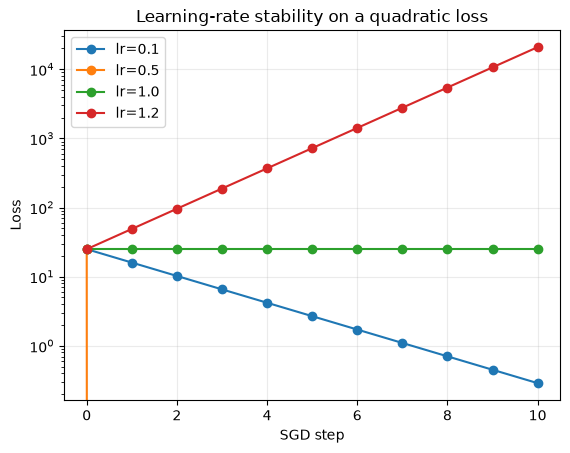

In [3]:
def run_sgd(learning_rate, steps=10, initial_weight=0.0):
    weight = initial_weight
    weights = [weight]

    for _ in range(steps):
        gradient = 2.0 * (weight - 5.0)
        weight -= learning_rate * gradient
        weights.append(weight)

    return weights


learning_rates = (0.1, 0.5, 1.0, 1.2)

for learning_rate in learning_rates:
    weights = run_sgd(learning_rate)
    losses = [(weight - 5.0) ** 2 for weight in weights]
    print(
        f"lr={learning_rate}: "
        f"final_weight={weights[-1]:.4f}, "
        f"final_loss={losses[-1]:.4f}"
    )
    plt.plot(losses, marker="o", label=f"lr={learning_rate}")

plt.xlabel("SGD step")
plt.ylabel("Loss")
plt.title("Learning-rate stability on a quadratic loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Practical gradient diagnostics

The report records missing gradients, norms, maxima, means, and finite-value status.

In [4]:
def gradient_report(model):
    results = []

    for name, parameter in model.named_parameters():
        if parameter.grad is None:
            results.append({
                "name": name,
                "grad_norm": None,
                "grad_max": None,
                "grad_mean": None,
                "finite": None,
                "status": "missing",
            })
            continue

        gradient = parameter.grad.detach()
        finite = torch.isfinite(gradient).all().item()
        results.append({
            "name": name,
            "grad_norm": gradient.float().norm().item(),
            "grad_max": gradient.abs().max().item(),
            "grad_mean": gradient.float().mean().item(),
            "finite": finite,
            "status": "ok" if finite else "non-finite",
        })

    return results


diagnostic_model = nn.Sequential(
    nn.Linear(4, 8),
    nn.Tanh(),
    nn.Linear(8, 2),
)
diagnostic_input = torch.randn(6, 4)
diagnostic_target = torch.randn(6, 2)
diagnostic_loss = (diagnostic_model(diagnostic_input) - diagnostic_target).square().mean()
diagnostic_loss.backward()

for row in gradient_report(diagnostic_model):
    print(row)

{'name': '0.weight', 'grad_norm': 1.0723011493682861, 'grad_max': 0.5359265208244324, 'grad_mean': -0.012980717234313488, 'finite': True, 'status': 'ok'}
{'name': '0.bias', 'grad_norm': 0.3707130551338196, 'grad_max': 0.2735852599143982, 'grad_mean': 0.016317125409841537, 'finite': True, 'status': 'ok'}
{'name': '2.weight', 'grad_norm': 1.2817834615707397, 'grad_max': 0.691188395023346, 'grad_mean': -0.0184231698513031, 'finite': True, 'status': 'ok'}
{'name': '2.bias', 'grad_norm': 0.743249237537384, 'grad_max': 0.7136291265487671, 'grad_mean': -0.4606809616088867, 'finite': True, 'status': 'ok'}


## Exercises

1. Change the deep-stack scale to `0.8` and `1.2`; compare the layer-wise curves.
2. Run the learning-rate experiment for 50 steps and inspect the trajectories.
3. Add `torch.isfinite()` checks to the training loop and deliberately create a non-finite value.
4. Add a residual connection to the deep stack and compare its gradient profile with the plain stack.